All configuration and model checks passed.
itmAC = 0.0, 0.0, 250.0
[{'name': 'CavityA', 'shape': 'cuboid', 'xC': -18.6115, 'yC': 4.5, 'zC': 245.0, 'length': 160.401, 'breadth': 20.0, 'height': 20.0, 'angleDeg': 0.0, 'xRefineFactor': 4.0, 'yRefineFactor': 10.0, 'zRefineFactor': 8.0}, {'name': 'CavityB', 'shape': 'cuboid', 'xC': -38.7847, 'yC': 47.0377, 'zC': 245.0, 'length': 265.076, 'breadth': 20.0, 'height': 20.0, 'angleDeg': 60.0, 'xRefineFactor': 4.0, 'yRefineFactor': 4.0, 'zRefineFactor': 4.0}, {'name': 'CavityC', 'shape': 'cuboid', 'xC': 481.337, 'yC': 4.5, 'zC': 245.0, 'length': 187.308, 'breadth': 20.0, 'height': 20.0, 'angleDeg': 0.0, 'xRefineFactor': 4.0, 'yRefineFactor': 4.0, 'zRefineFactor': 4.0}, {'name': 'CavityD', 'shape': 'cuboid', 'xC': 180.3316, 'yC': 442.3562, 'zC': 245.0, 'length': 97.756, 'breadth': 20.0, 'height': 20.0, 'angleDeg': 60.0, 'xRefineFactor': 4.0, 'yRefineFactor': 4.0, 'zRefineFactor': 4.0}]
[  0.   0. 250.]
[-31.3137  58.8578 250.    ]
[427.028   3.785

/home/koley/.conda/envs/pySeis1DNN/lib/python3.11/site-packages/pysurf96/wrapper.py:99: RuntimeWarning: overflow encountered in cast
  error = surfdisp96(


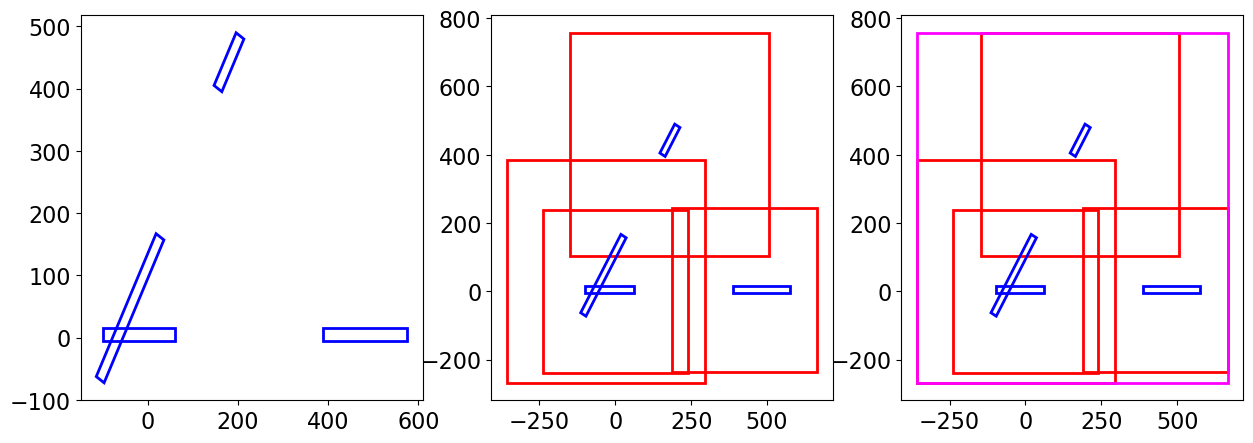

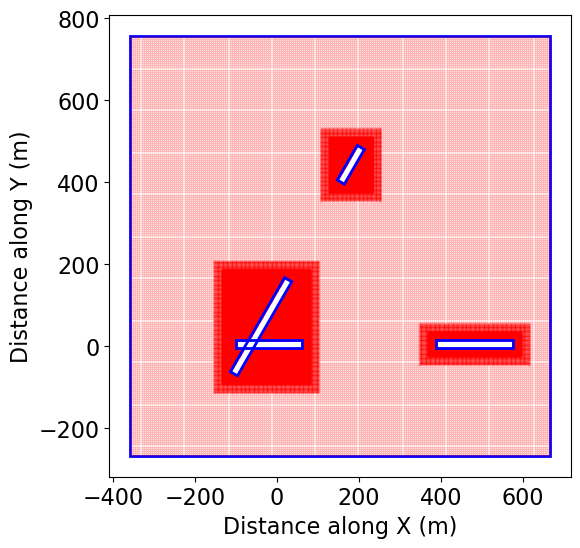

<Block x:[-357.94295996855044,666.1372135356021], y:[-267.7714599685505,757.1966599685504], z:[489.10921353560207,550.0] spaceT:[lgwt] intpType:[2] >
Block = 1
<Block x:[-357.94295996855044,666.1372135356021], y:[757.1966599685504,3000.0], z:[0.0,550.0] spaceT:[lgwt] intpType:[2] >
Block = 1
<Block x:[666.1372135356021,3000.0], y:[-3000.0,-267.7714599685505], z:[0.0,550.0] spaceT:[lgwt] intpType:[2] >
Block = 1
<Block x:[666.1372135356021,3000.0], y:[-267.7714599685505,757.1966599685504], z:[0.0,550.0] spaceT:[lgwt] intpType:[2] >
Block = 1
<Block x:[666.1372135356021,3000.0], y:[757.1966599685504,3000.0], z:[0.0,550.0] spaceT:[lgwt] intpType:[2] >
Block = 1
<Layer z: 550.0-3000.0, type: no_intersection, nblocks: 1>
<Block x:[-3000.0,3000.0], y:[-3000.0,3000.0], z:[550.0,3000.0] spaceT:[lgwt] intpType:[1] >
Block = 1


In [2]:
# script for visualizing the adaptive grid generation surrounding
# three different geometry cases
# 1) single spherical cavity of radius 20 m at 250 m depth
# 2) single cuboidal cavity of length 200m and breadth and height of 20 m
# 3) a set of cuboidal cavities representing one vertex of Einstein Telescope
import numpy as np
import os
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from scipy.io import loadmat

from pysurf96 import surf96
from modules import configLoader
from modules import validateInputs
from modules import NNGeometryNN
from modules import NNCompute
from modules import plotUtils

def main():

    # preparing for output visualization, set the fontsizes
    plotUtils.set_plot_style("medium")
    # load the config file, a generic config file for all cavity types
    # explored here
    configFile="/home/koley/CavityResults/AllConfigFiles/testGeometryTutorial/configParseMultiCavity.ini"
    config = configLoader.load_config(configFile)
    # load all cavities
    allCavities = configLoader.loadCavities('/home/koley/CavityResults/AllConfigFiles/testGeometryTutorial/MultiCavity.ini')
    # a single spherical cavity
    #allCavities = configLoader.loadCavities('/home/koley/CavityResults/AllConfigFiles/testGeometryTutorial/SingleSphCavityHalfSpace.ini')
    # a single cuboidal cavity
    #allCavities = configLoader.loadCavities('/home/koley/CavityResults/AllConfigFiles/testGeometryTutorial/SingleCubCavityHalfSpace.ini')
        
    validateInputs.validateInputs(config)

    figDataSave = '/home/koley/CavityResults/AllConfigFiles/testGeometryTutorial/multiCuboid.npz'

    thickness = config.thickness # units in meters
    vs = config.vS # units in m/s
    vp = config.vP # units in m/s
    rho = config.rho # units in kg/m^3
    fMin = config.fMin; fMax = config.fMax; # units in Hz
    lambdaFrac = config.lambdaFrac # fraction
    lambdaRes = config.lambdaRes; #must be greater than 4
    
    # given a cuboidal domain should be greater than sqrt of 
    xMaxGF = config.xMaxGF # maximum horizontal offset upto which displacements will be used
    zMaxGF = config.zMaxGF # maximum depth upto which displacements will be used
    maxRec = config.maxRec # same value of number of receivers that qseis can handle in one go check qsglobal.h
    xCenter = config.xCenter; yCenter = config.yCenter
    xMin = xCenter-config.xExtent; xMax = xCenter + config.xExtent # minimum and maximum of the simulation domain in X-direction (EW)
    yMin = yCenter-config.yExtent; yMax = yCenter + config.yExtent # maximum and minimum of the simulation domain in Y-direction (NS)
    zMin = 0.0; zMax = config.zExtent # maximum and minimum of the simulation domain in Z-direction (depth)

    # check if the GFs are generated up to correct hoizontal offsets
    xDiag = (xMax-xMin)*np.sqrt(2); yDiag = (yMax-yMin)*np.sqrt(2);
    if(xMaxGF<xDiag or xMaxGF<yDiag):
        raise ValueError("xMaxGF must be >= sqrt(2)x(xMax-xMin) and sqrt(2)x(yMax-yMin)")

    if(zMaxGF<zMax):
        raise ValueError("zMaxGF must be greater >= zMax")
        
    domXYBounds = (xMin,xMax,yMin,yMax)

    # specify test-mass locations, this was originally defined after cubeTop cubeBot definition
    itmAC = config.itmAC; itmAB = config.itmAB; etmCA = config.etmCA; etmBA = config.etmBA
            
    print('itmAC = ' + str(itmAC[0]) + ', ' + str(itmAC[1]) + ', ' + str(itmAC[2]))
    # make itmAC[2] negative, because in the configfile it is positive
    itmACUse = itmAC.copy(); itmACUse[2] = -np.abs(itmACUse[2])
    itmABUse = itmAB.copy(); itmABUse[2] = -np.abs(itmABUse[2])
    etmCAUse = etmCA.copy(); etmCAUse[2] = -np.abs(etmCAUse[2])
    etmBAUse = etmBA.copy(); etmBAUse[2] = -np.abs(etmBAUse[2])
            
    itmAll = np.vstack((itmACUse, itmABUse, etmCAUse, etmBAUse))
    print(allCavities)
    # an addition from the older version, where it is impoprtant to note that which cavity hosts
    # which test-mass
    tmInCavity = NNGeometryNN.findTMInCavity(allCavities, itmAll)

    print(tmInCavity)
    # generate the grid size required
    gridSize = NNCompute.getGridSize(thickness,vp, vs, rho, fMin, fMax, lambdaFrac, lambdaRes)
    print('grid size in each layer before partitioning = ' + str(gridSize))
        
    # get the background gridsize in the layer hosting the cavities
    hBGAll = NNGeometryNN.getHBG(thickness,allCavities,gridSize)

    print(hBGAll)
    # now get the refinement extent for all cavities
    etaUse = 0.5
    wallRefineWidthAll = NNGeometryNN.getRefineWidths(tmInCavity, allCavities,
                                                      hBGAll,eta=etaUse,minRefine=20.0,)
    print('wallRefineWidth = ')
    print(wallRefineWidthAll)

    # get the list of refne boxes for all Cavities separately
    refineBoxes = NNGeometryNN.makeRefineBoxesFromCavities(allCavities,wallRefineWidthAll,domainZBounds=(zMin,zMax))

    # first check plot
    fig1, ax1 = plt.subplots(1,3, figsize=(15,5))
    # just plot the cavities
    plotCavities(allCavities,fig1,ax1[0])
    # plot cavities and local refine boxes
    plotCavities(allCavities,fig1,ax1[1])
    for rfBox in refineBoxes:
        plotBox(rfBox,fig1,ax1[1],'red')
    #plotBox(refineBoxes[1],fig1,ax1[1],'k')
    
    # compute az and cubeTop and cubeBot directly from all the cavities
    cubeTopAll = np.zeros((len(allCavities),))
    cubeBotAll = np.zeros((len(allCavities),))
    cavDepthAll = np.zeros((len(allCavities)))

    for cavNo, cav in enumerate(allCavities):    
        if(cav["shape"]=="cuboid"):
            hBuf = 2.0*cav["height"]  #aangepast
            cubeTopAll[cavNo] = cav["zC"] - hBuf; cubeBotAll[cavNo] = cav["zC"] + hBuf
            cavDepthAll[cavNo] = cav["zC"]
        elif(cav["shape"] == 'sphere'):
            hBuf = 2*cav["radius"]
            cubeTopAll[cavNo] = cav["zC"] -hBuf ; cubeBotAll[cavNo] = cav["zC"] + hBuf
            cavDepthAll[cavNo] = cav["zC"]
        else:
            ValueError('Unsupported cavity type')
    # compute max and min to get global cubeTop and cubeBot
    cubeTop = min(cubeTopAll); cubeBot = max(cubeBotAll)

    print("CubeTop = " + str(cubeTop) +  'CubeBot = ' + str(cubeBot))

    # generate the grid size required
    gridSize = NNCompute.getGridSize(thickness,vp, vs, rho, fMin, fMax, lambdaFrac, lambdaRes)
    
    print('grid size in each layer before partitioning = ' + str(gridSize))
    
    # create the layers and partition
    layers, _, _, _, gridSize2 = NNGeometryNN.createAllLayers(xMin, xMax, yMin, yMax, thickness,
                                                                     zMax,vp,vs,rho,gridSize,cubeTop,cubeBot)
    print('New gridSize after partioning = '+ str(gridSize2))

    print('Total number of layers = ' + str(len(layers)))
    
    # plot cavities and local refine boxes and enclosing refineBox
    refineBox = NNGeometryNN.getEnclosingRefineBox(refineBoxes,layers[0])
    plotCavities(allCavities,fig1,ax1[2])
    plotBoxes(refineBoxes,fig1,ax1[2],'red')
    plotRefineBox(refineBox,fig1,ax1[2],'magenta')
    
    fig2, ax2 = plt.subplots(figsize=(6,6))
    for reaNo in range(0,1):
        
        for layerNo, layer in enumerate(layers):
            layer = layers[layerNo]

            # need to redefine cubeTop and cubeBot for multiple cavities
            layer.updateCubeInteraction(cubeTop, cubeBot)
            #layer.generateBlocks(xMin, xMax, yMin, yMax, cubeC, ax, ay, az, domXYBounds)
            layer.generateBlocksNew(refineBoxes=refineBoxes,domXYBounds=domXYBounds,
                                    domainZBounds=(zMin, zMax))
            
            print(layer)
            blkNo = 1
            for blk in layer.blocks:
                print(blk);
                print('Block = '+str(blkNo))
                if(blk.spaceType=='uniform'):
                    # plot the block, get the xy spacing
                    plotRefineBox(blk, fig2, ax2,'blue')
                    # generate the adaptive point cloud
                    xy_result = NNCompute.generate_adaptive_xy_pointcloud(cavities=allCavities,x_min=blk.xMin,x_max=blk.xMax,
                                                    y_min=blk.yMin, y_max=blk.yMax, dx_inside=1.0,
                                                    dy_inside=1.0, dx_near=1.0, dy_near=1.0, dx_mid=2.0,
                                                    dy_mid=2.0, dx_far=5.0, dy_far=5.0, near_frac=1.0/3.0, mid_frac=2.0/3.0,
                                                    near_cap=20.0, mid_cap=20.0, gap_tol=10.0)
                    gridX_flat = xy_result["gridX_flat"]
                    gridY_flat = xy_result["gridY_flat"]

                    # mask out points inside the cavity
                    maskCav = NNCompute.mask_points_outside_all_cavities(gridX_flat, gridY_flat, -250, allCavities)

                    gridX_flat = gridX_flat[maskCav]
                    gridY_flat = gridY_flat[maskCav]

                    ax2.plot(gridX_flat,gridY_flat,"r.",markersize=1,alpha=0.3,zorder=1)

                    plotCavities(allCavities, fig2, ax2)

                    np.savez(figDataSave, xData=gridX_flat, yData=gridY_flat, allCav=allCavities)
                    ax2.set_xlabel('Distance along X (m)')
                    ax2.set_ylabel('Distance along Y (m)')

                    #ax2.set_xlim(-400,400)
                    #ax2.set_ylim(-400,400)
                    #ax2.relim()
                    #ax2.autoscale_view()
                    ax2.set_aspect("equal", adjustable="box")

                    plt.show()


def plotCavities(allCavities, figA, axA):
    for cav in allCavities:
        if(cav['shape']=='cuboid'):
            xRect = cav['xC'] - cav['length'] / 2
            yRect = cav['yC'] - cav['breadth'] / 2

            rect = Rectangle((xRect, yRect),cav['length'],cav['breadth'],
                             angle=cav['angleDeg'],rotation_point='center',
                             linewidth=2,edgecolor="blue",facecolor="none",
                            zorder=10)
            axA.add_patch(rect)
        elif(cav['shape']=='sphere'):
            xySph = (cav['xC'],cav['yC'])
            sph = Circle(xySph, radius = cav['radius'],linewidth=2,
                         edgecolor="blue",facecolor="none",zorder=10)
            axA.add_patch(sph)
    #axA.relim()
    axA.autoscale_view()
    #axA.set_aspect("equal", adjustable="box")
    #plt.show()

def plotBoxes(refineBoxes, figA, axA, colVal):
    for cav in refineBoxes:
        xRect = cav.xMin
        yRect = cav.yMin

        l = cav.xMax - cav.xMin
        b = cav.yMax - cav.yMin

        print(l, b)

        rect = Rectangle((xRect, yRect),l,b,linewidth=2,
                         edgecolor=colVal,facecolor="none")
        axA.add_patch(rect)

        # Tell matplotlib the patch's bounds should count for axis limits
        axA.update_datalim([(cav.xMin, cav.yMin),(cav.xMax, cav.yMax)])

    axA.autoscale_view()
    #axA.set_aspect("equal", adjustable="box")
    #figA.canvas.draw_idle()
    #plt.show()

def plotBox(refineBox, figA, axA, colVal):
    xRect = refineBox.xMin
    yRect = refineBox.yMin

    l = refineBox.xMax - refineBox.xMin
    b = refineBox.yMax - refineBox.yMin

    print(l, b)

    rect = Rectangle(
        (xRect, yRect),l,b,linewidth=2,edgecolor=colVal,facecolor="none")

    axA.add_patch(rect)

    # Tell matplotlib the patch's bounds should count for axis limits
    axA.update_datalim([(refineBox.xMin, refineBox.yMin),
                        (refineBox.xMax, refineBox.yMax)])

    axA.autoscale_view()

def plotRefineBox(cav, figA, axA, colVal):
    xRect = cav.xMin
    yRect = cav.yMin

    l = cav.xMax - cav.xMin
    b = cav.yMax - cav.yMin

    print(l, b)

    rect = Rectangle(
        (xRect, yRect),l,b,linewidth=2,edgecolor=colVal,facecolor="none")

    axA.add_patch(rect)

    # Tell matplotlib the patch's bounds should count for axis limits
    axA.update_datalim([(cav.xMin, cav.yMin),(cav.xMax, cav.yMax)])

    axA.autoscale_view()
    #axA.set_aspect("equal", adjustable="box")
    #figA.canvas.draw_idle()
    #plt.show()

if __name__ == "__main__":
    main()

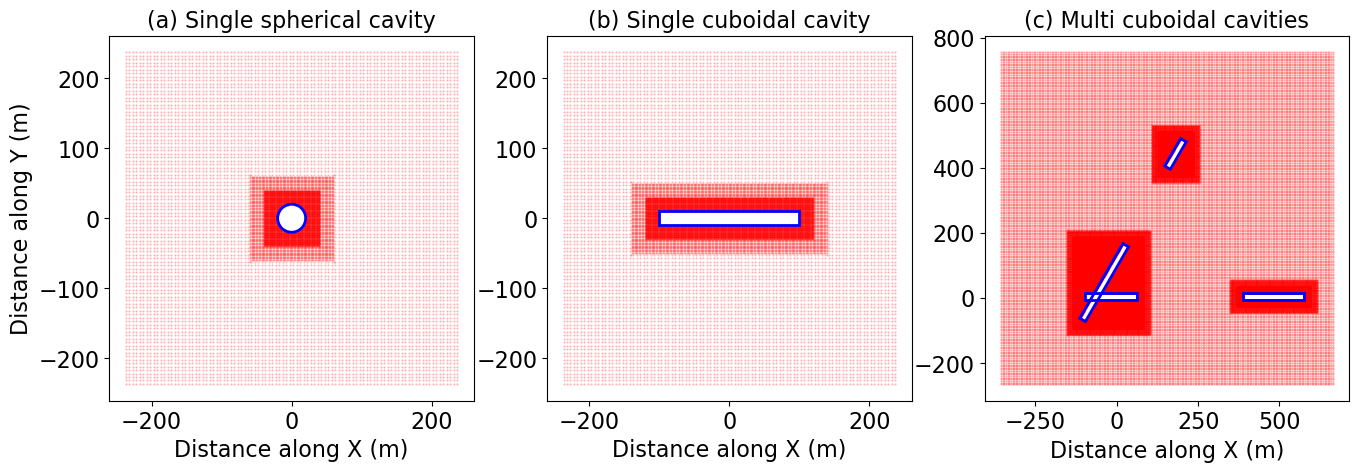

In [3]:
# reload all the previous saved data files for each of the cuboid types
# and plot it as 1x3 fig

# preparing for output visualization, set the fontsizes
plotUtils.set_plot_style("medium")

fig,ax = plt.subplots(1,3,figsize = (16,6))

# full figure save path
figSavePath = '/home/koley/CavityResults/AllConfigFiles/testGeometryTutorial/Figure3New.png' 
# load the spherical cavity case
figDataSph = '/home/koley/CavityResults/AllConfigFiles/testGeometryTutorial/singleSphere.npz'
loaded = np.load(figDataSph,allow_pickle=True)

ax[0].plot(loaded['xData'],loaded['yData'],"r.",markersize=1,alpha=0.3,zorder=1)
plotCavities(loaded['allCav'], fig, ax[0])
ax[0].set_xlabel('Distance along X (m)')
ax[0].set_ylabel('Distance along Y (m)')
ax[0].set_title('(a) Single spherical cavity')
ax[0].set_aspect("equal", adjustable="box")

# load the single cuboidal cavity case
figDataCub = '/home/koley/CavityResults/AllConfigFiles/testGeometryTutorial/singleCuboid.npz'
loaded = np.load(figDataCub,allow_pickle=True)

ax[1].plot(loaded['xData'],loaded['yData'],"r.",markersize=1,alpha=0.3,zorder=1)
plotCavities(loaded['allCav'], fig, ax[1])
ax[1].set_xlabel('Distance along X (m)')
#ax[0].set_ylabel('Distance along Y (m)')
ax[1].set_title('(b) Single cuboidal cavity')
ax[1].set_aspect("equal", adjustable="box")

# load the multicavity case
figDataMultiCub = '/home/koley/CavityResults/AllConfigFiles/testGeometryTutorial/multiCuboid.npz'
loaded = np.load(figDataMultiCub,allow_pickle=True)

ax[2].plot(loaded['xData'],loaded['yData'],"r.",markersize=1,alpha=0.3,zorder=1)
plotCavities(loaded['allCav'], fig, ax[2])
ax[2].set_xlabel('Distance along X (m)')
#ax[2].set_ylabel('Distance along Y (m)')
ax[2].set_title('(c) Multi cuboidal cavities')
ax[2].set_aspect("equal", adjustable="box")

fig.savefig(figSavePath, bbox_inches='tight')